> **실험 기록.** 속도 모델 설계 과정의 비교 실험이며 출력은 실행 당시 결과를 보존했다. 최종 모델은 `src/models/`, 공식 성능은 [docs/SPEED_MODEL.md](../docs/SPEED_MODEL.md), 노트북별 요약과 재실행 조건은 [notebooks/README.md](README.md)에 있다.

# 미관측 링크 계층 분리 평가 — 이웃 속도 피처는 어디서 통하고 어디서 깨지는가

**한 줄 요약**: 하나의 R²로 보고하던 "미관측 링크 성능"을 **이웃 관측 유무로 쪼개서** 다시 측정하고, 그 결과 드러난 문제와 해결책을 비교합니다.

---

## 왜 이 노트북이 필요한가

`02_derived_features_lightgbm.ipynb`에서 **인접 실측 이웃 속도**가 압도적으로 효과적이라는 게 확인됐습니다(R² 0.625 → 0.744). 하지만 그 숫자는 테스트 링크 전체를 한 덩어리로 평균낸 값입니다.

문제는 서울 도로가 예측 난이도 면에서 **성격이 전혀 다른 세 집단**으로 나뉜다는 것입니다.

| 계층 | 정의 | 배포 시 쓸 수 있는 정보 |
| --- | --- | --- |
| **A** | 5분 데이터에 속도가 관측되는 링크 | 자기 자신의 과거 속도 이력 (Model A) |
| **B** | 미관측 + 1홉 이내에 관측 링크가 있음 | 이웃의 실측 속도 |
| **C** | 미관측 + 1홉 이내에 관측 링크가 **없음** | 정적 피처(도로·지형·위상·시간·날씨·교통량)뿐 |

이웃 속도 피처는 정의상 **B에서만 값이 존재**하고 C에서는 결측입니다.
그런데 평가는 A·B·C를 섞어서 하니 **C에서 무슨 일이 일어나는지 아무도 모르는 상태**였습니다.

C는 서울 전체 링크의 7.2%, 연장 402km입니다. 에너지 최적 경로가 이 구간을 지나가면 그 구간의 속도 예측이 곧 에너지 추정의 신뢰도가 됩니다.

## 이 노트북이 답하는 질문

1. C 계층의 실제 예측 성능은 얼마인가?
2. 이웃 속도 피처를 넣으면 C는 어떻게 되는가?
3. 정적 피처(도로망 위상, 외부 컨텍스트)는 계층별로 얼마나 기여하는가?
4. 문제가 있다면 어떻게 고치는가?

## 방법 요약

- 관측 링크 44,960개를 **강제로 숨겨서** 미관측 상황을 재현합니다(GroupKFold).
- 분할을 **두 가지**로 합니다. 이웃 보유율이 분할 방식에 따라 극단적으로 달라지기 때문입니다.
  - **링크 랜덤분할**: 12번 노트북과 같은 방식. 링크를 무작위로 숨김 → 이웃 보유율이 높게 나옴
  - **공간 블록분할(2km)**: 지리적으로 인접한 링크를 통째로 숨김 → 실제 미관측 지역과 비슷한 상황
- 각 분할에서 테스트 링크를 **B(이웃 있음)/C(이웃 없음)** 로 나눠 R²·MAE를 따로 냅니다.
- 피처를 누적해가며(S1→S5) 계층별 기여도를 봅니다.

> **입력 스키마**: 이 노트북은 새 파이프라인 산출물 2개(`seoul_link_dimension.csv` 63,548행 = 링크당 1행, `seoul_link_speed_fact.csv` 15,094,335행 = 링크×날짜×시간당 1행)를 `LINK_ID`로 merge해서 씁니다. 옛 단일 병합 파일(`seoul_link_speed_dem_weather_merged.csv`, 5.2GB)은 정적 속성을 관측 행마다 최대 336번 중복 저장했고, 지금은 두 파일 합쳐 약 840MB입니다.

In [1]:
import platform
import time
from collections import defaultdict
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CACHE_DIR = INTERIM_DIR / "notebook_cache"
FIG_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
for d in (CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

DIMENSION_PATH = PROCESSED_DIR / "seoul_link_dimension.csv"   # pipeline/04 산출 (링크당 1행)
FACT_PATH = PROCESSED_DIR / "seoul_link_speed_fact.csv"       # pipeline/05 산출 (링크x날짜x시간)
LINK_SHP = INTERIM_DIR / "seoul_link.shp"                     # 공간 블록분할용 좌표
LEV6_SHP = RAW_DIR / "traffic" / "seoul_lev6_2024" / "seoul_link_lev6_2024.shp"
CACHE_PATH = CACHE_DIR / "nb13_feature_cache.parquet"

# macOS/Windows 모두에서 한글이 깨지지 않도록
plt.rcParams["font.family"] = "AppleGothic" if platform.system() == "Darwin" else "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
N_FOLDS = 3
SAMPLE_FRAC = 1.0          # 빠르게 돌려볼 때 0.15 정도로 낮추면 5분 안에 끝납니다(결론은 동일)
BLOCK_SIZE_M = 2000        # 공간 블록분할 격자 한 변 길이

COLOR_B = "#2a78d6"
COLOR_C = "#eb6834"


## 1. 서울 도로를 A / B / C로 나눈다

먼저 **실제 서울이 지금 어떤 상태인지**를 셉니다. 평가와는 별개로, 배포 시점에 마주하는 현실입니다.

- 관측 여부: 팩트 테이블에 속도 행이 있는가
- 이웃: 차원 테이블의 도로망 위상(`F_NODE`/`T_NODE`)으로 노드를 공유하는 1홉 인접 링크

In [2]:
dim = pd.read_csv(
    DIMENSION_PATH,
    dtype={"LINK_ID": str, "F_NODE": str, "T_NODE": str,
           "ROAD_RANK": str, "ROAD_TYPE": str, "ROAD_USE": str, "MULTI_LINK": str,
           "CONNECT": str, "REST_VEH": str, "REST_W": str, "REST_H": str, "C-ITS": str},
    encoding="utf-8-sig",
)
print(f"차원 테이블: {len(dim):,}행 x {len(dim.columns)}컬럼")

fact_links = pd.read_csv(FACT_PATH, dtype={"LINK_ID": str}, usecols=["LINK_ID"], encoding="utf-8-sig")
observed = set(fact_links["LINK_ID"].unique())
all_links = set(dim["LINK_ID"])
del fact_links

# 1홉 인접 그래프 (노드 공유)
node_to_links = defaultdict(set)
for lid, fn, tn in zip(dim["LINK_ID"], dim["F_NODE"], dim["T_NODE"]):
    node_to_links[fn].add(lid)
    node_to_links[tn].add(lid)

neighbors = defaultdict(set)
for group in node_to_links.values():
    for lid in group:
        neighbors[lid] |= (group - {lid})

unobserved = all_links - observed
tier_b = {l for l in unobserved if neighbors[l] & observed}
tier_c = unobserved - tier_b

tier_map = pd.Series("A 관측", index=sorted(all_links))
tier_map[sorted(tier_b)] = "B 미관측·이웃있음"
tier_map[sorted(tier_c)] = "C 미관측·이웃없음"
dim["tier"] = dim["LINK_ID"].map(tier_map)

summary = dim.groupby("tier").agg(링크수=("LINK_ID", "size"),
                                  연장_km=("LENGTH", lambda s: s.sum() / 1000))
summary["링크_비중"] = (summary["링크수"] / len(dim) * 100).round(1)
summary["연장_비중"] = (summary["연장_km"] / summary["연장_km"].sum() * 100).round(1)
summary["연장_km"] = summary["연장_km"].round(0)
print(summary.to_string())

차원 테이블: 63,548행 x 59컬럼


              링크수   연장_km  링크_비중  연장_비중
tier                                   
A 관측        44960  4858.0   70.7   80.3
B 미관측·이웃있음  14006   787.0   22.0   13.0
C 미관측·이웃없음   4582   402.0    7.2    6.6


In [3]:
print("=== 계층별 도로등급 구성 ===")
rank_name = {"101": "고속국도", "102": "도시고속국도", "103": "일반국도", "104": "특별광역시도",
             "105": "국가지원지방도", "106": "지방도", "107": "시군도", "108": "고속도로 연결램프"}
rank_tbl = (dim.assign(등급=dim["ROAD_RANK"].map(rank_name).fillna(dim["ROAD_RANK"]))
               .pivot_table(index="등급", columns="tier", values="LINK_ID", aggfunc="size", fill_value=0))
rank_tbl["관측률"] = (rank_tbl.get("A 관측", 0) / rank_tbl.sum(axis=1) * 100).round(1)
print(rank_tbl.sort_values("관측률").to_string())

=== 계층별 도로등급 구성 ===
tier      A 관측  B 미관측·이웃있음  C 미관측·이웃없음    관측률
등급                                           
시군도        886         425         238   57.2
특별광역시도   39058       13513        4342   68.6
고속국도       342           9           1   97.2
도시고속국도    1365          23           0   98.3
일반국도      3021          35           1   98.8
국가지원지방도    120           1           0   99.2
지방도        168           0           0  100.0


### 여기서 이미 하나가 정리됩니다

미관측 링크는 사실상 전부 **특별광역시도(시내 일반도로)** 입니다. 고속국도·도시고속국도·일반국도는 이미 97% 이상 관측되고 있습니다.

→ 서울 열린데이터광장의 **도시고속도로 5분단위 링크 속도(OA-22351)** 를 추가로 받아도 얻을 게 거의 없습니다. 이미 덮여 있는 구간이기 때문입니다. 추가 데이터를 찾는다면 **시내 일반도로의 지체를 설명하는 것**이어야 합니다.

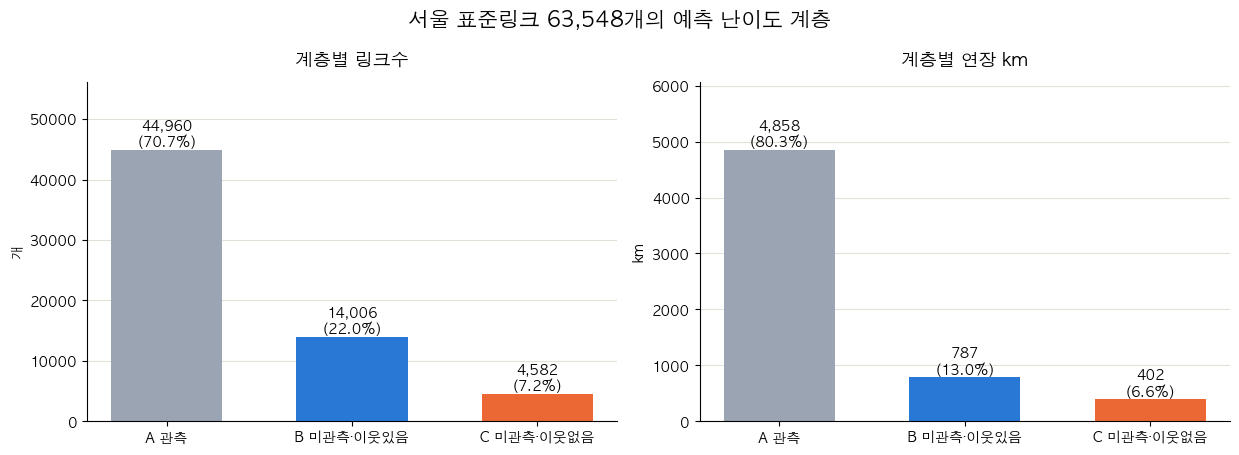

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
order = ["A 관측", "B 미관측·이웃있음", "C 미관측·이웃없음"]
colors = ["#9aa4b2", COLOR_B, COLOR_C]

for ax, col, unit in zip(axes, ["링크수", "연장_km"], ["개", "km"]):
    vals = summary.loc[order, col]
    pcts = summary.loc[order, "링크_비중" if col == "링크수" else "연장_비중"]
    bars = ax.bar(order, vals, color=colors, width=0.6)
    ax.set_title(f"계층별 {col.replace('_', ' ')}", fontsize=13, fontweight="bold", pad=12)
    ax.set_ylabel(unit)
    for bar, v, pct in zip(bars, vals, pcts):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,.0f}\n({pct}%)",
                ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.tick_params(axis="x", labelsize=10)

fig.suptitle("서울 표준링크 63,548개의 예측 난이도 계층", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_tier_abc_size.png", dpi=220, bbox_inches="tight")
plt.show()

## 2. 외부 피처는 정작 필요한 계층에 값이 있는가

12번 노트북에서 View-T 추정교통량의 기여가 +0.012에 그쳤습니다. 버스전용차로도 +0.003이었고, 팀에서 추가한 스쿨존/사고다발/과속방지턱도 "아주 조금"이었습니다.

가설: **효과가 없는 게 아니라, 정작 예측이 필요한 계층에 값이 없어서 평가에 안 잡히는 것**일 수 있습니다. 계층별 커버리지를 먼저 확인합니다.

In [5]:
EXTERNAL_CANDIDATES = ["traffic_volume_aadt", "bus_lane_ratio", "school_zone_count",
                       "accident_hotspot_count", "speed_bump_count"]
external_present = [c for c in EXTERNAL_CANDIDATES if c in dim.columns]
external_missing = [c for c in EXTERNAL_CANDIDATES if c not in dim.columns]
if external_missing:
    print(f"[주의] 차원 테이블에 없는 외부 피처: {external_missing}")
    print("       data/raw/traffic/ 에 원본을 받은 뒤 src/pipeline/04를 다시 돌리면 채워집니다.\n")

# View-T 상세도로망 Level6 네트워크가 덮는 ITS 링크 = '혼잡시간강도'를 받으면 붙일 수 있는 범위
lev6_links = set()
if LEV6_SHP.exists():
    lev6 = gpd.read_file(LEV6_SHP, columns=["up_its_id", "dw_its_id"])
    for c in ["up_its_id", "dw_its_id"]:
        lev6_links |= set(lev6[c].dropna().astype("int64").astype(str))

# 0은 '시설 없음'이라 커버리지가 아님 — 값이 실제로 존재하는(>0 또는 non-null) 링크만 센다
def covered(col: str) -> set:
    s = dim[["LINK_ID", col]].dropna()
    if col != "traffic_volume_aadt":
        s = s[s[col] > 0]
    return set(s["LINK_ID"])

tier_sets = {"A 관측": observed, "B 미관측·이웃있음": tier_b, "C 미관측·이웃없음": tier_c}
rows = []
for name, s in tier_sets.items():
    row = {"계층": name, "링크수": len(s)}
    for col in external_present:
        row[col] = f"{len(covered(col) & s)/len(s)*100:.1f}%"
    if lev6_links:
        row["View-T Level6"] = f"{len(lev6_links & s)/len(s)*100:.1f}%"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print()
print("→ 'View-T Level6'는 혼잡시간강도(상세도로망 Level6, csv)를 받았을 때 붙일 수 있는 범위입니다.")
print("  현재 교통량은 주요도로망 Level5.5 기준이라 시내 일반도로를 거의 못 덮습니다.")

        계층   링크수 traffic_volume_aadt bus_lane_ratio school_zone_count accident_hotspot_count speed_bump_count
      A 관측 44960               39.3%          10.1%             41.6%                   4.5%            16.1%
B 미관측·이웃있음 14006                1.5%           3.4%             43.5%                   2.5%            24.0%
C 미관측·이웃없음  4582                1.1%           0.0%             44.2%                   1.3%            34.4%

→ 'View-T Level6'는 혼잡시간강도(상세도로망 Level6, csv)를 받았을 때 붙일 수 있는 범위입니다.
  현재 교통량은 주요도로망 Level5.5 기준이라 시내 일반도로를 거의 못 덮습니다.


## 3. 데이터 로드 — 차원 + 팩트 결합

새 스키마에서는 정적 속성이 차원 테이블에 링크당 1행으로만 저장되므로, 학습용 테이블을 만들려면 `LINK_ID`로 merge합니다. 결과를 `data/interim/notebook_cache/`에 parquet으로 캐싱합니다.

In [6]:
# --- 피처 그룹 정의 (차원 테이블 컬럼 기준) ---
CAT_COLS = ["ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
            "REST_VEH", "REST_W", "REST_H", "C-ITS"]
BASE_STATIC = ["LANES", "MAX_SPD", "LENGTH", "elev_mean_m", "elev_delta_m", "slope_pct", "abs_slope_pct"]
# pipeline/04가 새로 만들어주는 정적 피처 — 전부 미관측 링크에서도 계산 가능
TOPO_COLS = [
    "f_node_node_in_degree", "f_node_incoming_max_spd_mean", "f_node_incoming_lanes_mean",
    "f_node_node_out_degree", "f_node_outgoing_max_spd_mean", "f_node_outgoing_lanes_mean",
    "f_node_node_total_degree",
    "t_node_node_in_degree", "t_node_incoming_max_spd_mean", "t_node_incoming_lanes_mean",
    "t_node_node_out_degree", "t_node_outgoing_max_spd_mean", "t_node_outgoing_lanes_mean",
    "t_node_node_total_degree",
    "upstream_max_spd_mean", "downstream_max_spd_mean", "upstream_lanes_mean", "downstream_lanes_mean",
    "node_complexity", "downstream_speed_delta",
    "slope_pct_clipped", "slope_outlier_flag", "is_uphill", "is_downhill", "steep_uphill",
    "slope_length_m", "max_spd_x_lanes", "length_x_node_complexity",
]
TOPO_COLS = [c for c in TOPO_COLS if c in dim.columns]
FACT_NUM = ["시간코드", "precip_mm", "traffic_volume_hourly", "traffic_volume_ratio"]
TARGET = "평균속도"


def build_cache() -> pd.DataFrame:
    dim_cols = ["LINK_ID"] + CAT_COLS + BASE_STATIC + TOPO_COLS + external_present
    static = dim[dim_cols].copy()

    chunks = []
    reader = pd.read_csv(FACT_PATH, dtype={"LINK_ID": str, "기준일": str},
                         encoding="utf-8-sig", chunksize=3_000_000)
    for chunk in reader:
        chunk = chunk.dropna(subset=[TARGET])
        for c in FACT_NUM + [TARGET]:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce").astype("float32")
        chunks.append(chunk[["LINK_ID", "기준일", TARGET] + FACT_NUM])
    out = pd.concat(chunks, ignore_index=True)

    d = pd.to_datetime(out["기준일"], format="%Y%m%d")
    out["dow"] = d.dt.weekday.astype("int8")
    out["is_weekend"] = (out["dow"] >= 5).astype("int8")
    h = out["시간코드"].astype("float32")
    out["hour_sin"] = np.sin(2 * np.pi * h / 24).astype("float32")
    out["hour_cos"] = np.cos(2 * np.pi * h / 24).astype("float32")

    out = out.merge(static, on="LINK_ID", how="left")          # <-- 차원 x 팩트 결합
    for c in BASE_STATIC + TOPO_COLS + external_present:
        out[c] = pd.to_numeric(out[c], errors="coerce").astype("float32")

    # 공간 블록분할용 링크 중심좌표
    geo = gpd.read_file(LINK_SHP, columns=["LINK_ID"])
    geo["LINK_ID"] = geo["LINK_ID"].astype(str)
    cent = geo.geometry.centroid
    out = out.merge(pd.DataFrame({"LINK_ID": geo["LINK_ID"],
                                  "cx": cent.x.astype("float32"),
                                  "cy": cent.y.astype("float32")}), on="LINK_ID", how="left")
    out.to_parquet(CACHE_PATH, index=False)
    return out


df = pd.read_parquet(CACHE_PATH) if CACHE_PATH.exists() else build_cache()
for c in CAT_COLS:
    df[c] = df[c].astype("category")
print(f"{len(df):,}행 x {len(df.columns)}컬럼 | 링크 {df['LINK_ID'].nunique():,} | "
      f"기간 {df['기준일'].min()}~{df['기준일'].max()}")
print(f"도로망 위상·파생 피처 {len(TOPO_COLS)}개 | 외부 컨텍스트 {len(external_present)}개: {external_present}")

15,094,335행 x 62컬럼 | 링크 44,960 | 기간 20260707~20260720
도로망 위상·파생 피처 28개 | 외부 컨텍스트 5개: ['traffic_volume_aadt', 'bus_lane_ratio', 'school_zone_count', 'accident_hotspot_count', 'speed_bump_count']


## 4. 인접 실측 이웃 속도 피처

12번 노트북과 동일하게, 링크×시각 속도 행렬에 희소 인접행렬을 곱해 "1홉 관측 이웃들의 그 시각 실측 평균속도"를 계산합니다.

**핵심 규칙**: 폴드마다 **그 폴드의 train 링크만 이웃으로 인정**합니다. 숨긴 링크(=미관측 가정)의 실측값이 이웃 피처로 새어 들어가면 평가가 부풀려집니다.

부산물로 링크별 **이웃 보유 여부**가 나오는데, 이게 곧 그 폴드의 B/C 구분 기준이 됩니다.

In [7]:
df["tm_key"] = df["기준일"] + "_" + df["시간코드"].astype(int).astype(str)

link_ids = np.sort(df["LINK_ID"].unique())
link_pos = {l: i for i, l in enumerate(link_ids)}
tm_keys = np.sort(df["tm_key"].unique())
tm_pos = {t: i for i, t in enumerate(tm_keys)}

row_i = df["LINK_ID"].map(link_pos).to_numpy()
col_i = df["tm_key"].map(tm_pos).to_numpy()
speed_mat = np.zeros((len(link_ids), len(tm_keys)), dtype="float32")
valid_mat = np.zeros_like(speed_mat)
speed_mat[row_i, col_i] = df[TARGET].to_numpy()
valid_mat[row_i, col_i] = 1.0

edge_src, edge_dst = [], []
observed_arr = set(link_ids)
for l in link_ids:
    i = link_pos[l]
    for n in neighbors.get(l, ()):
        if n in observed_arr:
            edge_src.append(i)
            edge_dst.append(link_pos[n])
edge_src, edge_dst = np.array(edge_src), np.array(edge_dst)
edge_dst_link = link_ids[edge_dst]
print(f"이웃 행렬 {speed_mat.shape} | 간선 {len(edge_src):,}개")


def neighbor_speed(allowed_links):
    # allowed_links만 이웃으로 인정한 (링크x시각) 실측 평균속도 행렬과, 링크별 이웃 보유 여부를 반환
    keep = np.isin(edge_dst_link, list(allowed_links))
    adj = csr_matrix((np.ones(int(keep.sum()), "float32"), (edge_src[keep], edge_dst[keep])),
                     shape=(len(link_ids), len(link_ids)))
    num, den = adj @ speed_mat, adj @ valid_mat
    with np.errstate(invalid="ignore", divide="ignore"):
        mat = num / den
    mat[den == 0] = np.nan
    return mat, np.asarray(adj.sum(axis=1)).ravel() > 0

이웃 행렬 (44960, 336) | 간선 145,764개


## 5. 평가 설계

### 두 가지 분할을 모두 돌리는 이유

이웃 보유율이 분할 방식에 따라 극단적으로 달라집니다.

| 분할 | 숨기는 방식 | 테스트 링크의 이웃 보유율 |
| --- | --- | --- |
| 링크 랜덤분할 | 링크를 무작위로 1/3 숨김 | **약 93%** (숨겨도 옆 링크는 대개 살아있음) |
| 공간 블록분할 | 2km 격자를 통째로 숨김 | **약 9%** (지역 전체가 사라짐) |
| *(실제 서울)* | — | **75.3%** (B 14,006 / B+C 18,588) |

실제는 두 극단 사이입니다. 그래서 **한쪽만 보면 결론이 왜곡**됩니다.

### 피처 세트

| | 구성 |
| --- | --- |
| **S1** | 도로 기본(차로/제한속도/연장/등급/고도/경사) + 시간(시각·요일·주말) + 날씨(강수) |
| **S2** | S1 + **도로망 위상·파생** (노드 차수, 상·하류 제한속도·차로수, 노드 복잡도, 경사 파생 등 — `pipeline/04` 신규) |
| **S3** | S2 + 외부 컨텍스트 (View-T 교통량, 그리고 원본이 있으면 버스전용차로/스쿨존/사고다발/과속방지턱) |
| **S4** | S3 + 인접 실측 이웃 속도 **(원본 — 없으면 결측)** |
| **S5** | S3 + 인접 실측 이웃 속도 **(결측 시 계층평균으로 폴백)** |
| **S6** | 분리 모델 — B 링크는 S4, C 링크는 S3 예측을 사용 |

S5·S6는 이 노트북에서 발견한 문제의 **해결책 후보**입니다.

In [8]:
TIME_COLS = ["시간코드", "dow", "is_weekend", "hour_sin", "hour_cos"]
S1_COLS = BASE_STATIC + TIME_COLS + ["precip_mm"] + CAT_COLS
S2_COLS = S1_COLS + TOPO_COLS
S3_COLS = S2_COLS + external_present + ["traffic_volume_hourly", "traffic_volume_ratio"]

FEATURE_SETS = {
    "S1 도로기본+시간+날씨": S1_COLS,
    "S2 +도로망 위상·파생": S2_COLS,
    "S3 +외부 컨텍스트": S3_COLS,
    "S4 +이웃속도(원본)": S3_COLS + ["nb_speed"],
    "S5 +이웃속도(결측폴백)": S3_COLS + ["nb_speed_filled"],
}
SPLIT_MODEL = "S6 분리모델(B=S4, C=S3)"

if SAMPLE_FRAC < 1.0:
    df = df.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"샘플 {SAMPLE_FRAC:.0%} → {len(df):,}행")

row_i = df["LINK_ID"].map(link_pos).to_numpy()
col_i = df["tm_key"].map(tm_pos).to_numpy()
df["block"] = ((df["cx"] // BLOCK_SIZE_M).astype(int).astype(str) + "_" +
               (df["cy"] // BLOCK_SIZE_M).astype(int).astype(str))
print(f"피처 수: S1={len(S1_COLS)} S2={len(S2_COLS)} S3={len(S3_COLS)} | "
      f"공간 블록 {df['block'].nunique():,}개 ({BLOCK_SIZE_M/1000:.0f}km 격자)")

피처 수: S1=22 S2=50 S3=57 | 공간 블록 187개 (2km 격자)


In [9]:
def run_split(split_name, groups):
    # 폴드마다: 이웃 피처 재계산 -> 피처 세트별 학습 -> 테스트를 B/C로 나눠 평가
    records, importance = [], None
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=N_FOLDS).split(df, groups=groups)):
        t0 = time.time()
        train_links = set(df["LINK_ID"].values[tr])
        nb_mat, has_nb = neighbor_speed(train_links)
        df["nb_speed"] = nb_mat[row_i, col_i]

        # 결측 폴백: ROAD_RANK x MAX_SPD x 시간코드 계층평균 (train에서만 계산 — 누수 없음)
        key = ["ROAD_RANK", "MAX_SPD", "시간코드"]
        lut = df.iloc[tr].groupby(key, observed=True)[TARGET].mean().rename("fb").reset_index()
        fb = df[key].merge(lut, on=key, how="left")["fb"].to_numpy()
        fb = np.where(np.isnan(fb), df[TARGET].values[tr].mean(), fb)
        df["nb_speed_filled"] = np.where(df["nb_speed"].isna(), fb, df["nb_speed"])

        te_has_nb = pd.Series(has_nb, index=link_ids).reindex(df["LINK_ID"].values[te]).to_numpy()
        y_te = df[TARGET].values[te]

        preds = {}
        for name, cols in FEATURE_SETS.items():
            model = lgb.LGBMRegressor(objective="regression", n_estimators=300, learning_rate=0.05,
                                      num_leaves=63, random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)
            model.fit(df[cols].iloc[tr], df[TARGET].values[tr], categorical_feature=CAT_COLS)
            preds[name] = model.predict(df[cols].iloc[te])
            if name.startswith("S4") and importance is None:
                importance = pd.DataFrame({"feature": model.feature_name_,
                                           "gain": model.booster_.feature_importance("gain")})

        preds[SPLIT_MODEL] = np.where(te_has_nb, preds["S4 +이웃속도(원본)"], preds["S3 +외부 컨텍스트"])

        for name, pred in preds.items():
            for bucket, mask in [("전체", np.ones(len(te), bool)),
                                 ("B 이웃있음", te_has_nb), ("C 이웃없음", ~te_has_nb)]:
                if mask.sum() < 100:
                    continue
                records.append({"split": split_name, "fold": fold, "feats": name, "bucket": bucket,
                                "n": int(mask.sum()), "r2": r2_score(y_te[mask], pred[mask]),
                                "mae": mean_absolute_error(y_te[mask], pred[mask])})
        print(f"  [{split_name}] fold{fold} {time.time()-t0:.0f}s | "
              f"test 링크 {len(set(df['LINK_ID'].values[te])):,} | 이웃 보유 {te_has_nb.mean():.1%}")
    return pd.DataFrame(records), importance


block_name = f"공간 블록분할({BLOCK_SIZE_M//1000}km)"
res_random, imp_random = run_split("링크 랜덤분할", df["LINK_ID"].values)
res_block, _ = run_split(block_name, df["block"].values)
results = pd.concat([res_random, res_block], ignore_index=True)
results.to_csv(CACHE_DIR / "nb13_results.csv", index=False)
print("저장:", CACHE_DIR / "nb13_results.csv")

  [링크 랜덤분할] fold0 189s | test 링크 14,987 | 이웃 보유 93.6%


  [링크 랜덤분할] fold1 189s | test 링크 14,986 | 이웃 보유 93.4%


  [링크 랜덤분할] fold2 185s | test 링크 14,987 | 이웃 보유 93.7%


  [공간 블록분할(2km)] fold0 2181s | test 링크 14,986 | 이웃 보유 8.8%


  [공간 블록분할(2km)] fold1 303s | test 링크 14,988 | 이웃 보유 10.1%


  [공간 블록분할(2km)] fold2 184s | test 링크 14,986 | 이웃 보유 8.8%
저장: data/interim/notebook_cache/nb13_results.csv


## 6. 결과

In [10]:
ALL_SETS = list(FEATURE_SETS) + [SPLIT_MODEL]
agg = results.groupby(["split", "bucket", "feats"])[["r2", "mae"]].mean().round(3)
for split in results["split"].unique():
    print(f"\n{'='*76}\n{split}\n{'='*76}")
    sub = agg.loc[split]
    print("\n[R²]")
    print(sub["r2"].unstack(0).reindex(index=ALL_SETS, columns=["전체", "B 이웃있음", "C 이웃없음"]).to_string())
    print("\n[MAE km/h]")
    print(sub["mae"].unstack(0).reindex(index=ALL_SETS, columns=["전체", "B 이웃있음", "C 이웃없음"]).to_string())


링크 랜덤분할

[R²]
bucket                  전체  B 이웃있음  C 이웃없음
feats                                     
S1 도로기본+시간+날씨        0.526   0.531   0.410
S2 +도로망 위상·파생        0.556   0.562   0.424
S3 +외부 컨텍스트          0.568   0.574   0.432
S4 +이웃속도(원본)         0.701   0.716   0.411
S5 +이웃속도(결측폴백)       0.700   0.715   0.400
S6 분리모델(B=S4, C=S3)  0.702   0.716   0.432

[MAE km/h]
bucket                  전체  B 이웃있음  C 이웃없음
feats                                     
S1 도로기본+시간+날씨        6.200   6.196   6.262
S2 +도로망 위상·파생        5.984   5.970   6.182
S3 +외부 컨텍스트          5.911   5.896   6.136
S4 +이웃속도(원본)         4.658   4.551   6.218
S5 +이웃속도(결측폴백)       4.676   4.564   6.293
S6 분리모델(B=S4, C=S3)  4.653   4.551   6.136

공간 블록분할(2km)

[R²]
bucket                  전체  B 이웃있음  C 이웃없음
feats                                     
S1 도로기본+시간+날씨        0.496   0.681   0.439
S2 +도로망 위상·파생        0.534   0.707   0.482
S3 +외부 컨텍스트          0.544   0.713   0.492
S4 +이웃속도(원본)         0.414   0.780   0.314
S5 +이웃속

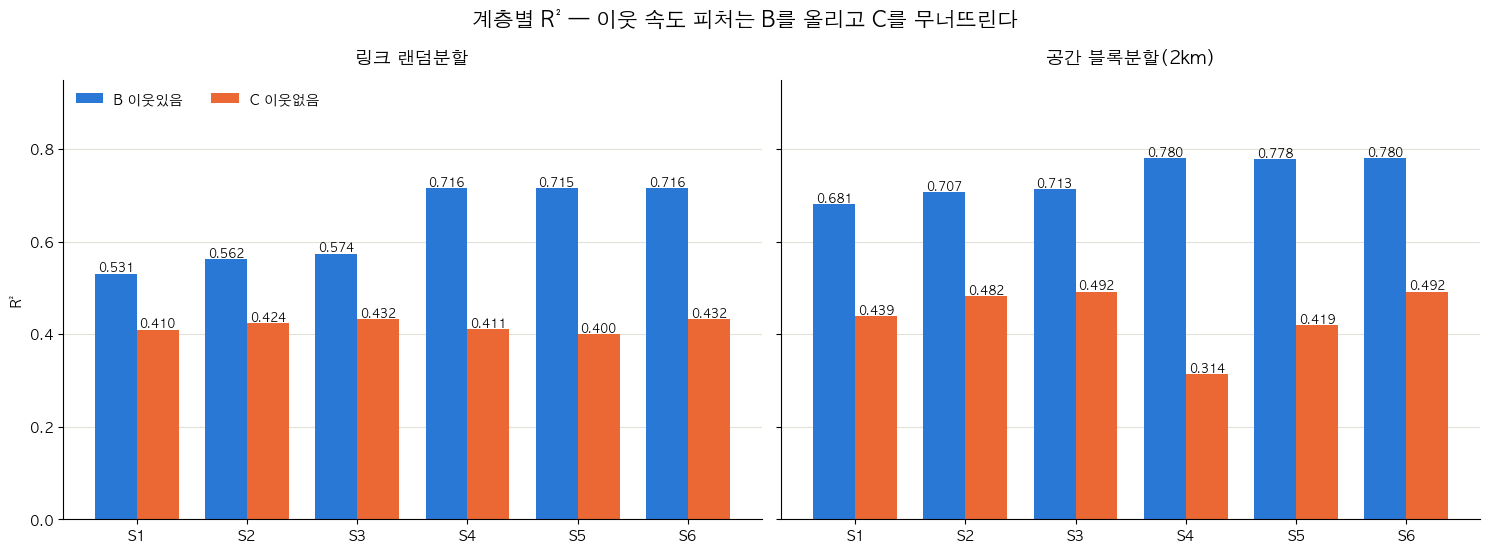

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharey=True)

for ax, split in zip(axes, ["링크 랜덤분할", block_name]):
    sub = agg.loc[split, "r2"].unstack(0)
    x = np.arange(len(ALL_SETS))
    w = 0.38
    ax.bar(x - w/2, sub.loc[ALL_SETS, "B 이웃있음"], w, label="B 이웃있음", color=COLOR_B)
    ax.bar(x + w/2, sub.loc[ALL_SETS, "C 이웃없음"], w, label="C 이웃없음", color=COLOR_C)
    for xi, s in zip(x, ALL_SETS):
        ax.text(xi - w/2, sub.loc[s, "B 이웃있음"], f"{sub.loc[s,'B 이웃있음']:.3f}",
                ha="center", va="bottom", fontsize=8.5, fontweight="bold")
        ax.text(xi + w/2, sub.loc[s, "C 이웃없음"], f"{sub.loc[s,'C 이웃없음']:.3f}",
                ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    ax.set_xticks(x, [s.split()[0] for s in ALL_SETS])
    ax.set_title(split, fontsize=13, fontweight="bold", pad=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)

axes[0].set_ylabel("R²")
axes[0].legend(frameon=False, ncols=2, loc="upper left")
axes[0].set_ylim(0, 0.95)
fig.suptitle("계층별 R² — 이웃 속도 피처는 B를 올리고 C를 무너뜨린다", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_tier_bc_r2.png", dpi=220, bbox_inches="tight")
plt.show()

## 7. 피처 그룹별 기여도 — 계층에 따라 부호가 다르다

각 단계에서 R²가 얼마나 움직였는지를 계층별로 봅니다. 전체 평균 하나만 볼 때는 안 보이던 게 드러납니다.

In [12]:
steps = [("S1 도로기본+시간+날씨", "S2 +도로망 위상·파생", "도로망 위상·파생"),
         ("S2 +도로망 위상·파생", "S3 +외부 컨텍스트", "외부 컨텍스트"),
         ("S3 +외부 컨텍스트", "S4 +이웃속도(원본)", "인접 이웃속도")]
rows = []
for split in results["split"].unique():
    sub = agg.loc[split, "r2"].unstack(0)
    for bucket in ["B 이웃있음", "C 이웃없음"]:
        row = {"분할": split, "계층": bucket}
        for a, b, label in steps:
            row[f"Δ {label}"] = round(sub.loc[b, bucket] - sub.loc[a, bucket], 3)
        rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

          분할     계층  Δ 도로망 위상·파생  Δ 외부 컨텍스트  Δ 인접 이웃속도
     링크 랜덤분할 B 이웃있음        0.031      0.012      0.142
     링크 랜덤분할 C 이웃없음        0.014      0.008     -0.021
공간 블록분할(2km) B 이웃있음        0.026      0.006      0.067
공간 블록분할(2km) C 이웃없음        0.043      0.010     -0.178


### 원인

훈련 데이터의 대부분은 이웃 속도가 **있는** 행입니다. LightGBM은 그 강한 피처에 크게 의존하도록 학습됩니다.
그런데 C 계층에서는 그 피처가 **결측**입니다. 모델은 결측 경로로 빠지면서, 정작 남은 정적 피처를 제대로 쓰도록 학습되지 않은 상태로 예측하게 됩니다.

즉 **훈련 시 피처 가용성과 배포 시 피처 가용성이 어긋나는 문제**이고, 하필 **가장 정보가 부족한 링크**에서 발생합니다.

### 해결책 비교

| | 방식 | 장점 | 단점 |
| --- | --- | --- | --- |
| **S5** | 이웃 결측을 계층평균으로 채움 | 모델 1개로 끝남 | 가짜 값이라 C 회복이 부분적 |
| **S6** | B/C를 다른 모델로 예측 | C 손실 없음, 각 계층 최적 | 모델 2개 관리 |

In [13]:
blk_r2 = agg.loc[block_name, "r2"].unstack(0)
blk_mae = agg.loc[block_name, "mae"].unstack(0)

fix = []
for split in results["split"].unique():
    r2s, maes = agg.loc[split, "r2"].unstack(0), agg.loc[split, "mae"].unstack(0)
    for name in ["S3 +외부 컨텍스트", "S4 +이웃속도(원본)", "S5 +이웃속도(결측폴백)", SPLIT_MODEL]:
        fix.append({"분할": split, "구성": name,
                    "B R²": r2s.loc[name, "B 이웃있음"], "C R²": r2s.loc[name, "C 이웃없음"],
                    "전체 R²": r2s.loc[name, "전체"], "전체 MAE": maes.loc[name, "전체"]})
fix_df = pd.DataFrame(fix)
print(fix_df.to_string(index=False))

best = fix_df[fix_df["분할"] == block_name].sort_values("전체 R²", ascending=False).iloc[0]
print(f"\n→ 공간 블록분할 기준 최고 구성: {best['구성']}  "
      f"(전체 R²={best['전체 R²']:.3f}, C R²={best['C R²']:.3f})")

print("\n=== S4 모델 피처 중요도 상위 15 (링크 랜덤분할 fold0) ===")
imp = imp_random.sort_values("gain", ascending=False)
imp["gain_share"] = (imp["gain"] / imp["gain"].sum() * 100).round(2)
imp["그룹"] = np.select(
    [imp["feature"] == "nb_speed", imp["feature"].isin(TOPO_COLS),
     imp["feature"].isin(external_present + ["traffic_volume_hourly", "traffic_volume_ratio"]),
     imp["feature"].isin(TIME_COLS)],
    ["이웃속도", "위상·파생", "외부", "시간"], default="도로기본")
print(imp.head(15)[["feature", "그룹", "gain_share"]].to_string(index=False))
print("\n=== 그룹별 gain 합계 ===")
print(imp.groupby("그룹")["gain_share"].sum().sort_values(ascending=False).round(2).to_string())

          분할                  구성  B R²  C R²  전체 R²  전체 MAE
     링크 랜덤분할         S3 +외부 컨텍스트 0.574 0.432  0.568   5.911
     링크 랜덤분할        S4 +이웃속도(원본) 0.716 0.411  0.701   4.658
     링크 랜덤분할      S5 +이웃속도(결측폴백) 0.715 0.400  0.700   4.676
     링크 랜덤분할 S6 분리모델(B=S4, C=S3) 0.716 0.432  0.702   4.653
공간 블록분할(2km)         S3 +외부 컨텍스트 0.713 0.492  0.544   6.055
공간 블록분할(2km)        S4 +이웃속도(원본) 0.780 0.314  0.414   6.564
공간 블록분할(2km)      S5 +이웃속도(결측폴백) 0.778 0.419  0.498   6.298
공간 블록분할(2km) S6 분리모델(B=S4, C=S3) 0.780 0.492  0.556   5.942

→ 공간 블록분할 기준 최고 구성: S6 분리모델(B=S4, C=S3)  (전체 R²=0.556, C R²=0.492)

=== S4 모델 피처 중요도 상위 15 (링크 랜덤분할 fold0) ===
                     feature    그룹  gain_share
                    nb_speed  이웃속도       67.17
                     MAX_SPD  도로기본        6.10
             max_spd_x_lanes 위상·파생        2.44
                      LENGTH  도로기본        2.35
t_node_incoming_max_spd_mean 위상·파생        2.13
                   ROAD_TYPE  도로기본        2.03
         traffic_vo

## 8. 관측 링크(A 계층) — 시간 분할 기준

A 계층은 문제 성격이 다릅니다. 도로를 새로 만나는 게 아니라 **아는 도로의 미래 시각**을 맞히는 문제이므로, 링크를 숨기는 게 아니라 **날짜로 자릅니다**(과거 → 미래).

배포 시 A 계층에서 실제로 쓰는 방법인 **이력 조회표(링크 × 시간대 × 주중/주말 평균)** 를 그대로 평가합니다.

In [14]:
hist = df[["LINK_ID", "기준일", "시간코드", "is_weekend", TARGET]]
dates = np.sort(hist["기준일"].unique())
n_train_days = int(len(dates) * 0.7)
cut = dates[n_train_days]
tr_h, te_h = hist[hist["기준일"] < cut], hist[hist["기준일"] >= cut]

lut = tr_h.groupby(["LINK_ID", "시간코드", "is_weekend"], observed=True)[TARGET].mean().rename("pred").reset_index()
glb = tr_h.groupby(["시간코드", "is_weekend"], observed=True)[TARGET].mean().rename("g").reset_index()
ev = te_h.merge(lut, on=["LINK_ID", "시간코드", "is_weekend"], how="left") \
         .merge(glb, on=["시간코드", "is_weekend"], how="left")
hit_rate = ev["pred"].notna().mean()          # 폴백 없이 조회표로 바로 맞은 비율
ev["pred"] = ev["pred"].fillna(ev["g"]).fillna(tr_h[TARGET].mean())

a_r2 = r2_score(ev[TARGET], ev["pred"])
a_mae = mean_absolute_error(ev[TARGET], ev["pred"])
print(f"train {dates[0]}~{dates[n_train_days-1]} ({n_train_days}일) / "
      f"test {cut}~{dates[-1]} ({len(dates)-n_train_days}일)")
print(f"이력 조회표(링크×시간대×주중/주말): R²={a_r2:.4f}  MAE={a_mae:.3f} km/h  (n={len(ev):,})")
print(f"조회표 적중률(폴백 안 쓴 비율): {hit_rate:.1%}")

train 20260707~20260715 (9일) / test 20260716~20260720 (5일)
이력 조회표(링크×시간대×주중/주말): R²=0.8773  MAE=2.754 km/h  (n=5,393,618)
조회표 적중률(폴백 안 쓴 비율): 100.0%


## 9. 배포 시나리오 종합

각 계층에 실제로 적용할 방법과 그 성능을 하나의 표로 모읍니다. **분할 방식이 계층마다 다른 게 맞습니다** — 배포 시 각 계층이 실제로 마주하는 문제가 다르기 때문입니다.

- A: 날짜 분할(과거→미래) — 아는 도로의 미래 시각
- B·C: 공간 블록분할 — 본 적 없는 지역의 도로

In [15]:
deploy = pd.DataFrame([
    {"계층": "A 관측", "링크수": len(observed), "방법": "이력 조회표(링크×시간×주중/주말)",
     "평가 분할": "날짜 순차", "R²": round(a_r2, 3), "MAE": round(a_mae, 2)},
    {"계층": "B 미관측·이웃있음", "링크수": len(tier_b), "방법": "LightGBM + 인접 실측 이웃속도 (S4)",
     "평가 분할": f"공간 블록 {BLOCK_SIZE_M//1000}km",
     "R²": round(blk_r2.loc["S4 +이웃속도(원본)", "B 이웃있음"], 3),
     "MAE": round(blk_mae.loc["S4 +이웃속도(원본)", "B 이웃있음"], 2)},
    {"계층": "C 미관측·이웃없음", "링크수": len(tier_c), "방법": "LightGBM 정적 전부 (S3, 이웃속도 제외)",
     "평가 분할": f"공간 블록 {BLOCK_SIZE_M//1000}km",
     "R²": round(blk_r2.loc["S3 +외부 컨텍스트", "C 이웃없음"], 3),
     "MAE": round(blk_mae.loc["S3 +외부 컨텍스트", "C 이웃없음"], 2)},
])
deploy["링크 비중"] = (deploy["링크수"] / len(all_links) * 100).round(1).astype(str) + "%"
print(deploy[["계층", "링크수", "링크 비중", "방법", "평가 분할", "R²", "MAE"]].to_string(index=False))

w = deploy["링크수"] / deploy["링크수"].sum()
print(f"\n링크수 가중 평균 MAE: {(deploy['MAE'] * w).sum():.2f} km/h")
print("※ R²는 계층마다 분모(분산)가 달라 가중평균이 의미 없으므로 MAE만 합산합니다.")

        계층   링크수 링크 비중                           방법     평가 분할    R²  MAE
      A 관측 44960 70.7%          이력 조회표(링크×시간×주중/주말)     날짜 순차 0.877 2.75
B 미관측·이웃있음 14006 22.0%   LightGBM + 인접 실측 이웃속도 (S4) 공간 블록 2km 0.780 5.49
C 미관측·이웃없음  4582  7.2% LightGBM 정적 전부 (S3, 이웃속도 제외) 공간 블록 2km 0.492 5.99

링크수 가중 평균 MAE: 3.59 km/h
※ R²는 계층마다 분모(분산)가 달라 가중평균이 의미 없으므로 MAE만 합산합니다.


In [16]:
c_static = blk_r2.loc["S3 +외부 컨텍스트", "C 이웃없음"]
c_naive = blk_r2.loc["S4 +이웃속도(원본)", "C 이웃없음"]
c_fill = blk_r2.loc["S5 +이웃속도(결측폴백)", "C 이웃없음"]
b_before = blk_r2.loc["S3 +외부 컨텍스트", "B 이웃있음"]
b_after = blk_r2.loc["S4 +이웃속도(원본)", "B 이웃있음"]
topo_gain_c = blk_r2.loc["S2 +도로망 위상·파생", "C 이웃없음"] - blk_r2.loc["S1 도로기본+시간+날씨", "C 이웃없음"]
ext_gain_c = blk_r2.loc["S3 +외부 컨텍스트", "C 이웃없음"] - blk_r2.loc["S2 +도로망 위상·파생", "C 이웃없음"]

lines = [
    "=" * 72, "결론", "=" * 72,
    f"1. C 계층(미관측·이웃없음)은 서울 링크의 {len(tier_c)/len(all_links)*100:.1f}%, "
    f"연장 {summary.loc['C 미관측·이웃없음', '연장_km']:.0f}km입니다.",
    "",
    "2. 인접 이웃 속도 피처는 계층에 따라 효과의 부호가 반대입니다.",
    f"   - B 계층: R² {b_before:.3f} -> {b_after:.3f}   ({b_after-b_before:+.3f})",
    f"   - C 계층: R² {c_static:.3f} -> {c_naive:.3f}   ({c_naive-c_static:+.3f})",
    "   훈련 때 있던 피처가 배포 때 사라지는 계층이 있기 때문입니다.",
    "",
    "3. 해결책은 분리 모델(S6)입니다. C에서 이웃속도를 빼면 손실이 사라집니다.",
    f"   결측 폴백(S5)은 {c_fill:.3f}까지만 회복합니다.",
    "",
    "4. 정적 피처의 C 계층 기여도:",
    f"   - 도로망 위상·파생({len(TOPO_COLS)}개): {topo_gain_c:+.3f}",
    f"   - 외부 컨텍스트({len(external_present)+2}개): {ext_gain_c:+.3f}",
]
if external_missing:
    lines += ["", f"   [미측정] {external_missing} 는 원본이 없어 이번 실험에서 빠졌습니다.",
              "   data/raw/traffic/에 원본을 받고 src/pipeline/04를 다시 돌린 뒤",
              "   이 노트북을 재실행하면 S3에 자동으로 포함됩니다."]
print("\n".join(lines))

결론
1. C 계층(미관측·이웃없음)은 서울 링크의 7.2%, 연장 402km입니다.

2. 인접 이웃 속도 피처는 계층에 따라 효과의 부호가 반대입니다.
   - B 계층: R² 0.713 -> 0.780   (+0.067)
   - C 계층: R² 0.492 -> 0.314   (-0.178)
   훈련 때 있던 피처가 배포 때 사라지는 계층이 있기 때문입니다.

3. 해결책은 분리 모델(S6)입니다. C에서 이웃속도를 빼면 손실이 사라집니다.
   결측 폴백(S5)은 0.419까지만 회복합니다.

4. 정적 피처의 C 계층 기여도:
   - 도로망 위상·파생(28개): +0.043
   - 외부 컨텍스트(7개): +0.010


## 팀 액션 제안

### 1. 파이프라인 — 미관측 링크 모델을 둘로 나눈다

미관측 링크를 한 모델로 처리하지 않고 이웃 보유 여부로 분기해야 하며, 이는 `src/models/02_build_model_bc.py`의 B/C 분리로 반영되었습니다.
링크별 이웃 보유 여부는 이 노트북 1절의 `tier_b` / `tier_c` 집합으로 결정되며, 관측 링크 목록만 있으면 재계산됩니다.

### 2. 보고서 — 성능을 계층별로 보고한다

"미관측 링크 R² 0.6x" 한 줄 대신 9절의 3계층 표를 씁니다. 심사에서 "커버리지 70%인데 나머지는?"이라는 질문이 나오면 이 표가 곧 답입니다.

### 3. 추가 데이터 — C 계층을 덮는 것만 가치가 있다

- **받을 것: View-T 혼잡시간강도 (상세도로망 Level6, csv)** — 링크별로 "총 통행시간 중 혼잡경계속도 이하로 주행한 시간 비율(%)"입니다. 차량 GPS 프로브에서 **속도로부터 산출된 지표**라 우리 타깃과 같은 단위계이고, 무엇보다 **미관측 링크에도 값이 존재**합니다. 연평균 값이므로 `src/pipeline/04`(차원 테이블) 쪽에 붙입니다. `data/raw/traffic/seoul_lev6_2024/seoul_link_lev6_2024.shp`에 `up_its_id`/`dw_its_id`가 있어 `LINK_ID`에 바로 조인됩니다.
- **같이 받을 것: 추정교통량 주말분** — 현재 보유분은 2024년 평일 기준이라, 주말 예측 시 평일 값이 그대로 들어가고 있습니다.
- **받지 않아도 되는 것: 서울 열린데이터광장 도시고속도로 5분단위 링크 속도(OA-22351)** — 도시고속국도는 이미 관측률 98%입니다.

### 4. 후속 실험

- 버스전용차로/스쿨존/사고다발/과속방지턱 원본을 받은 뒤 재실행 → S3에 자동 포함되어 **C 계층 기여도**가 측정됩니다(전체 평균으로는 판단 불가).
- 혼잡시간강도 결합 후 C 계층 R² 재측정 — 유의미하게 오르면 채택, 아니면 정적 피처 추가는 중단.

---

### 한계

- B/C 구분은 관측 링크를 **강제로 숨겨서** 재현한 것입니다. 실제 미관측 링크는 관측 대상에서 빠진 이유(교통량이 적거나 검지기 미설치)가 있어 분포가 다를 수 있습니다.
- 공간 블록분할은 이웃 보유율이 약 9%로, 실제 미관측 링크(75.3%)보다 훨씬 낮습니다. 계층별 R²는 안정적으로 읽되, **분할별 '전체' R²는 계층 구성비가 달라 직접 비교하면 안 됩니다.**
- View-T 교통량의 시간대 매칭(시간코드 1 = 0~1시)은 `src/pipeline/05`의 순서 기반 가정을 그대로 따릅니다.
- `data/interim/notebook_cache/`의 캐시와 결과 CSV는 이 노트북 전용 산출물로, 재실행하면 다시 생깁니다.